# 03 · Spark: delay propagation chains + weather
**Question:** which airports and hours start delay cascades, and how much of a departure delay is *inherited from the previous flight of the same aircraft* vs. caused by *weather at the origin*?

**Inputs:** `data/flights_utc` (notebook 02) and `data/weather/parquet` (weather download notebook).
**Outputs:** `data/propagation/` (flight-level features, cascade table, airport×hour summary) for MongoDB Atlas and the dashboard later.

**Method**
1. Keep flown flights with a tail number. Order each aircraft's flights by actual departure time (UTC) and use a window `lag` to fetch the previous flight.
2. Link two flights only if the aircraft really continued from where it landed (`prev_dest == origin`) and the ground time is 0–12 h.
3. *Inherited delay* = previous arrival delay minus the slack in the schedule: `max(0, prev_arr_delay - max(0, scheduled_turnaround - MIN_TURN_MIN))`.
4. A **cascade** starts at a flight that is delayed 15+ min with no inherited delay, and continues while the next flights inherit delay. Cascade depth and size come from a running window count.
5. Join weather at the origin by hour and classify each delayed departure: inherited / weather / other.


In [1]:
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, Window, functions as F
try:
    import duckdb          # only needed for the local "ask it twice" check
except ImportError:
    duckdb = None

In [2]:
RUN_ON = "gcp"        # "local" = laptop (local[4]) ; "gcp" = Dataproc cluster reading/writing Cloud Storage
BUCKET = "flightdelay-olivia-2026"   # bucket name only (not a secret); used when RUN_ON = "gcp"

class GS(str):
    """gs:// path that supports the same OUT / "name" syntax as pathlib.Path"""
    def __truediv__(self, other): return GS(self.rstrip("/") + "/" + str(other))

if RUN_ON == "gcp":
    FLIGHTS_UTC = GS(f"gs://{BUCKET}/silver/flights_utc")
    WX_PQ       = GS(f"gs://{BUCKET}/weather/parquet")
    TZ_CSV      = GS(f"gs://{BUCKET}/meta/airport_tz.csv")
    OUT         = GS(f"gs://{BUCKET}/gold")
else:
    PROJECT = Path(os.path.expanduser("~/Desktop/ADSP32030_Scalable/Project"))
    FLIGHTS_UTC = PROJECT/"data/flights_utc"
    WX_PQ = PROJECT/"data/weather/parquet"
    TZ_CSV = PROJECT/"data/meta/airport_tz.csv"
    OUT = PROJECT/"data/propagation"; OUT.mkdir(parents=True, exist_ok=True)

RUN_YEARS = None        # e.g. [2024] to check results quickly; None = all years 2010-2026
MIN_TURN_MIN = 30         # assumed minimum turnaround (minutes); schedule slack above this absorbs delay
MAX_GROUND_H = 12         # a gap longer than this breaks the chain (overnight rest)
DELAY_MIN = 15            # BTS definition of "delayed"

builder = (SparkSession.builder.appName("delay-propagation")
           .config("spark.sql.shuffle.partitions", "400")
           .config("spark.sql.session.timeZone", "UTC"))
if RUN_ON == "local":
    builder = (builder.master("local[4]")                       # 4 cores: fewer tasks share the memory at once
               .config("spark.driver.memory", "8g")
               .config("spark.driver.bindAddress", "127.0.0.1").config("spark.driver.host", "127.0.0.1"))
else:
    builder = (builder.config("spark.sql.defaultCatalog", "spark_catalog")
               .config("spark.sql.extensions", ""))
spark = builder.getOrCreate()                                   # on Dataproc the cluster manager (YARN) is already configured
spark.sparkContext.setLogLevel("WARN")
print("Spark", spark.version, "| run on:", RUN_ON, "| cores:", spark.sparkContext.defaultParallelism, "| years:", RUN_YEARS or "all")


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/20 04:03:03 INFO SparkEnv: Registering MapOutputTracker
26/11/20 04:03:03 INFO SparkEnv: Registering BlockManagerMaster
26/11/20 04:03:03 INFO SparkEnv: Registering BlockManagerMasterHeartbeat
26/11/20 04:03:03 INFO SparkEnv: Registering OutputCommitCoordinator


Spark 3.5.3 | run on: gcp | cores: 2 | years: all


### 0 · Check that all inputs are there
Runs on the laptop (`RUN_ON = "local"`) and on the cluster (`"gcp"`). Compares row counts, years and columns with what the earlier notebooks produced, so a missing upload shows up here and not an hour into the run.

In [3]:
# input check: row counts, years, airports, required columns (expected values come from notebooks 00-02)
EXPECTED = {"flights_utc rows": 105_631_230, "weather observations": 10_660_339, "weather airports": 50, "airport_tz rows": 410}
REQUIRED = ["Year","FlightDate","Reporting_Airline","Tail_Number","Flight_Number_Reporting_Airline","Origin","Dest","origin_tz",
            "CRSDepTime","sched_dep_utc","dep_utc","sched_arr_utc","arr_utc","Cancelled","Diverted","DepDelay","ArrDelay",
            "CarrierDelay","WeatherDelay","NASDelay","SecurityDelay","LateAircraftDelay"]
ok = True
def show(name, got, exp=None):
    global ok
    good = (exp is None) or (got == exp)
    ok &= good
    print(f"{'OK      ' if good else 'MISMATCH'} {name:24s} {got:>14,}" + ("" if exp is None or good else f"   (expected {exp:,})"))

fl = spark.read.parquet(str(FLIGHTS_UTC))
show("flights_utc rows", fl.count(), EXPECTED["flights_utc rows"])
years = sorted(r[0] for r in fl.select("Year").distinct().collect())
good = years == list(range(2010, 2027)); ok &= good
print(f"{'OK      ' if good else 'MISMATCH'} years found: {years[0]}-{years[-1]} ({len(years)} years)" + ("" if good else f"  -> {years}"))
missing_cols = [c for c in REQUIRED if c not in fl.columns]; ok &= not missing_cols
print(f"{'OK      ' if not missing_cols else 'MISMATCH'} required columns" + (f"  missing: {missing_cols}" if missing_cols else " present"))

wx_in = spark.read.parquet(str(WX_PQ))
show("weather observations", wx_in.count(), EXPECTED["weather observations"])
show("weather airports", wx_in.select("airport").distinct().count(), EXPECTED["weather airports"])
show("airport_tz rows", spark.read.csv(str(TZ_CSV), header=True).count(), EXPECTED["airport_tz rows"])
print("\nALL INPUTS PRESENT - safe to run the rest" if ok else "\nSOMETHING IS MISSING - fix the upload / paths before continuing")

OK       flights_utc rows            105,631,230


OK       years found: 2010-2026 (17 years)
OK       required columns present


OK       weather observations         10,660,339


OK       weather airports                     50
OK       airport_tz rows                     410

ALL INPUTS PRESENT - safe to run the rest


## 1 · Flown flights with a usable tail number

In [4]:
fu = spark.read.parquet(str(FLIGHTS_UTC))
if RUN_YEARS: fu = fu.filter(F.col("Year").isin(RUN_YEARS))
print(f"{fu.count():,} flights in scope")
# most common 'tail numbers' - junk placeholders show up as huge counts
fu.groupBy("Tail_Number").count().orderBy(F.desc("count")).show(5)

105,631,230 flights in scope


+-----------+------+
|Tail_Number| count|
+-----------+------+
|       NULL|443965|
|     N486HA| 51221|
|     N487HA| 50734|
|     N476HA| 50442|
|     N480HA| 49787|
+-----------+------+
only showing top 5 rows



In [5]:
JUNK_TAILS = ["UNKNOWN"]          # add any placeholder you see above
base = (fu.filter((F.col("Cancelled") == 0) & (F.col("Diverted") == 0)
                  & F.col("Tail_Number").isNotNull() & (F.col("Tail_Number") != "") & ~F.col("Tail_Number").isin(JUNK_TAILS)
                  & F.col("sched_dep_utc").isNotNull() & F.col("dep_utc").isNotNull()
                  & F.col("sched_arr_utc").isNotNull() & F.col("arr_utc").isNotNull()
                  & F.col("DepDelay").isNotNull() & F.col("ArrDelay").isNotNull())
          .select("Year","FlightDate","Reporting_Airline","Tail_Number","Flight_Number_Reporting_Airline",
                  "Origin","Dest","origin_tz","CRSDepTime","sched_dep_utc","dep_utc","sched_arr_utc","arr_utc",
                  "DepDelay","ArrDelay","CarrierDelay","WeatherDelay","NASDelay","SecurityDelay","LateAircraftDelay"))
n_base = base.count()
print(f"{n_base:,} flights usable for chains")

103,396,805 flights usable for chains


## 2 · Link each flight to the aircraft's previous flight (window `lag`)

In [6]:
order_cols = ["dep_utc", "sched_dep_utc", "Flight_Number_Reporting_Airline"]
w = Window.partitionBy("Tail_Number").orderBy(*order_cols)
w_cum = w.rowsBetween(Window.unboundedPreceding, Window.currentRow)

ts = lambda c: F.unix_timestamp(c)
p = (base
     .withColumn("prev_dest",           F.lag("Dest").over(w))
     .withColumn("prev_arr_utc",        F.lag("arr_utc").over(w))
     .withColumn("prev_sched_arr_utc",  F.lag("sched_arr_utc").over(w))
     .withColumn("prev_arr_delay",      F.lag("ArrDelay").over(w))
     .withColumn("ground_min",          (ts("dep_utc") - ts("prev_arr_utc")) / 60)
     .withColumn("sched_turn_min",      (ts("sched_dep_utc") - ts("prev_sched_arr_utc")) / 60)
     .withColumn("linked", (F.col("prev_dest") == F.col("Origin"))
                           & F.col("ground_min").between(0, MAX_GROUND_H * 60)
                           & (F.col("sched_turn_min") >= 0))
     .withColumn("linked", F.coalesce("linked", F.lit(False)))
     .withColumn("slack_min",     F.greatest(F.lit(0.0), F.col("sched_turn_min") - F.lit(MIN_TURN_MIN)))
     .withColumn("inherited_min", F.when(F.col("linked"), F.greatest(F.lit(0.0), F.col("prev_arr_delay") - F.col("slack_min")))
                                   .otherwise(F.lit(0.0)))
     # a new chain starts whenever the flight does NOT inherit delay
     .withColumn("chain_start", F.when(F.col("inherited_min") > 0, 0).otherwise(1))
     .withColumn("chain_id", F.sum("chain_start").over(w_cum)))

wc = Window.partitionBy("Tail_Number", "chain_id").orderBy(*order_cols)
wc_all = Window.partitionBy("Tail_Number", "chain_id")
pairs = (p.withColumn("depth", F.row_number().over(wc) - 1)                  # 0 = root of the chain
          .withColumn("root_origin",       F.first("Origin").over(wc))
          .withColumn("root_origin_tz",    F.first("origin_tz").over(wc))
          .withColumn("root_dep_delay",    F.first("DepDelay").over(wc))
          .withColumn("root_sched_dep_utc",F.first("sched_dep_utc").over(wc))
          .withColumn("chain_len",         F.count("*").over(wc_all))
          .drop("chain_start"))
print("columns:", pairs.columns)

columns: ['Year', 'FlightDate', 'Reporting_Airline', 'Tail_Number', 'Flight_Number_Reporting_Airline', 'Origin', 'Dest', 'origin_tz', 'CRSDepTime', 'sched_dep_utc', 'dep_utc', 'sched_arr_utc', 'arr_utc', 'DepDelay', 'ArrDelay', 'CarrierDelay', 'WeatherDelay', 'NASDelay', 'SecurityDelay', 'LateAircraftDelay', 'prev_dest', 'prev_arr_utc', 'prev_sched_arr_utc', 'prev_arr_delay', 'ground_min', 'sched_turn_min', 'linked', 'slack_min', 'inherited_min', 'chain_id', 'depth', 'root_origin', 'root_origin_tz', 'root_dep_delay', 'root_sched_dep_utc', 'chain_len']


In [7]:
# materialise once (both window shuffles), then everything below reads this Parquet
(pairs.write.mode("overwrite").partitionBy("Year").parquet(str(OUT/"flight_chains")))
pairs = spark.read.parquet(str(OUT/"flight_chains"))
print(f"{pairs.count():,} rows written to {OUT/'flight_chains'}")

26/11/20 04:04:12 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


103,396,805 rows written to gs://flightdelay-olivia-2026/gold/flight_chains


## 3 · First result: how much delay is inherited?

In [8]:
res = (pairs.filter("linked")
       .agg(F.count("*").alias("linked_pairs"),
            F.avg(F.when(F.col("prev_arr_delay") >= DELAY_MIN, F.col("DepDelay"))).alias("avg_dep_delay_after_late_inbound"),
            F.avg(F.when(F.col("prev_arr_delay") < DELAY_MIN,  F.col("DepDelay"))).alias("avg_dep_delay_after_ontime_inbound"),
            F.avg((F.col("inherited_min") > 0).cast("double")).alias("share_flights_inheriting_delay")).toPandas())
print(f"linked pairs: {res.linked_pairs[0]:,}  ({100*res.linked_pairs[0]/pairs.count():.1f}% of usable flights)")
res

linked pairs: 94,550,204  (91.4% of usable flights)


,linked_pairs,avg_dep_delay_after_late_inbound,avg_dep_delay_after_ontime_inbound,share_flights_inheriting_delay
0,94550204,35.068131,1.374242,0.125738


In [9]:
# of the departures delayed 15+ min, what share inherited 15+ min from the previous flight?
d = pairs.filter(F.col("DepDelay") >= DELAY_MIN)
tot = d.count()
inh = d.filter(F.col("inherited_min") >= DELAY_MIN).count()
print(f"delayed departures: {tot:,}   inherited >=15 min: {inh:,}  = {100*inh/tot:.1f}%")

delayed departures: 19,424,121   inherited >=15 min: 6,532,437  = 33.6%


## 4 · Ask it twice: same linking logic in DuckDB
The identical rule is written as SQL and run on the same input. Linked-pair counts and the delay averages should agree (tiny differences are possible where two flights share the exact same timestamp).

In [10]:
if RUN_ON == "gcp":
    print("DuckDB check reads local files: run it in the local notebook (RUN_ON = 'local'); skipped on the cluster.")
else:
    Y = (RUN_YEARS or [2024])[0]
    sql = f"""
    WITH b AS (
      SELECT * FROM read_parquet('{FLIGHTS_UTC}/**/*.parquet', hive_partitioning=true)
      WHERE Year = {Y} AND Cancelled = 0 AND Diverted = 0 AND Tail_Number IS NOT NULL AND Tail_Number <> ''
            AND Tail_Number NOT IN ({",".join("'"+t+"'" for t in JUNK_TAILS)})
            AND sched_dep_utc IS NOT NULL AND dep_utc IS NOT NULL AND sched_arr_utc IS NOT NULL AND arr_utc IS NOT NULL
            AND DepDelay IS NOT NULL AND ArrDelay IS NOT NULL),
    l AS (
      SELECT *, lag(Dest) OVER w AS prev_dest, lag(arr_utc) OVER w AS prev_arr, lag(sched_arr_utc) OVER w AS prev_sarr,
                lag(ArrDelay) OVER w AS prev_ad
      FROM b WINDOW w AS (PARTITION BY Tail_Number ORDER BY dep_utc, sched_dep_utc, Flight_Number_Reporting_Airline)),
    k AS (
      SELECT *, (epoch(dep_utc) - epoch(prev_arr)) / 60 AS ground_min, (epoch(sched_dep_utc) - epoch(prev_sarr)) / 60 AS sturn
      FROM l)
    SELECT count(*) FILTER (WHERE prev_dest = Origin AND ground_min BETWEEN 0 AND {MAX_GROUND_H*60} AND sturn >= 0) AS linked_pairs,
           avg(DepDelay) FILTER (WHERE prev_dest = Origin AND ground_min BETWEEN 0 AND {MAX_GROUND_H*60} AND sturn >= 0 AND prev_ad >= {DELAY_MIN}) AS avg_dep_delay_after_late_inbound
    FROM k"""
    dk = duckdb.connect().execute(sql).df()
    sp = (pairs.filter((F.col("Year") == Y) & F.col("linked"))
               .agg(F.count("*").alias("linked_pairs"),
                    F.avg(F.when(F.col("prev_arr_delay") >= DELAY_MIN, F.col("DepDelay"))).alias("avg_dep_delay_after_late_inbound")).toPandas())
    print("Spark :", sp.iloc[0].to_dict()); print("DuckDB:", dk.iloc[0].to_dict())
    rel = abs(sp.linked_pairs[0] - dk.linked_pairs[0]) / max(1, dk.linked_pairs[0])
    print(f"relative difference in linked pairs: {rel:.5f}")

DuckDB check reads local files: run it in the local notebook (RUN_ON = 'local'); skipped on the cluster.


## 5 · Cascades: which airports and hours start them?

In [11]:
chains = (pairs.groupBy("Tail_Number", "chain_id")
          .agg(F.first("root_origin").alias("root_origin"), F.first("root_origin_tz").alias("tz"),
               F.first("root_dep_delay").alias("root_dep_delay"), F.first("root_sched_dep_utc").alias("root_sched_dep_utc"),
               F.count("*").alias("chain_len"),
               F.sum(F.when(F.col("depth") > 0, F.col("inherited_min")).otherwise(0.0)).alias("downstream_inherited_min"),
               F.max("Year").alias("Year")))
cascades = (chains.filter((F.col("chain_len") >= 2) & (F.col("root_dep_delay") >= DELAY_MIN))
            .withColumn("root_local_hour", F.hour(F.from_utc_timestamp("root_sched_dep_utc", F.col("tz")))))
cascades.write.mode("overwrite").parquet(str(OUT/"cascades"))
cascades = spark.read.parquet(str(OUT/"cascades"))
print(f"{cascades.count():,} cascades (root delayed 15+ min, at least one downstream flight inherits delay)")
cascades.agg(F.avg("chain_len").alias("avg_len"), F.expr("percentile_approx(chain_len, 0.9)").alias("p90_len"),
             F.max("chain_len").alias("max_len"), F.sum("downstream_inherited_min").alias("total_inherited_min")).show()

3,849,908 cascades (root delayed 15+ min, at least one downstream flight inherits delay)


+------------------+-------+-------+-------------------+
|           avg_len|p90_len|max_len|total_inherited_min|
+------------------+-------+-------+-------------------+
|2.7157261939765833|      4|     20|       3.34886763E8|
+------------------+-------+-------+-------------------+



In [12]:
deps = pairs.groupBy(F.col("Origin").alias("root_origin")).agg(F.count("*").alias("departures"))
by_ap = (cascades.groupBy("root_origin").agg(F.count("*").alias("cascades"), F.avg("chain_len").alias("avg_len"),
                                             F.sum("downstream_inherited_min").alias("inherited_min"))
         .join(deps, "root_origin")
         .withColumn("cascades_per_1000_deps", F.round(1000 * F.col("cascades") / F.col("departures"), 2))
         .toPandas())
big = by_ap[by_ap.departures >= 20000]
print("Most cascades started (count):");            display(big.sort_values("cascades", ascending=False).head(10))
print("Highest rate (per 1,000 departures), airports with >= 20k departures:")
display(big.sort_values("cascades_per_1000_deps", ascending=False).head(10))

Most cascades started (count):


,root_origin,cascades,avg_len,inherited_min,departures,cascades_per_1000_deps
310,DFW,272540,2.496815,20532466.0,4373848,62.31
122,ATL,262857,2.556188,19731482.0,5883027,44.68
339,ORD,260877,2.618038,22809509.0,4693123,55.59
61,DEN,193265,2.716943,14948193.0,4106005,47.07
283,CLT,129650,2.538442,10128837.0,2689262,48.21
304,PHX,107154,2.715223,7984380.0,2825579,37.92
234,IAH,105299,2.523367,8529831.0,2405525,43.77
177,LAX,104016,2.740838,8849597.0,3308306,31.44
56,LAS,97905,2.853858,7456074.0,2550130,38.39
376,MCO,97315,2.671695,8560925.0,2176120,44.72


Highest rate (per 1,000 departures), airports with >= 20k departures:


,root_origin,cascades,avg_len,inherited_min,departures,cascades_per_1000_deps
104,SFB,6416,2.597880,618126.0,81487,78.74
123,AZA,3619,2.416966,260431.0,49276,73.44
185,PGD,3530,2.400000,308490.0,52330,67.46
310,DFW,272540,2.496815,20532466.0,4373848,62.31
357,MDW,79519,2.965933,6300069.0,1327330,59.91
87,PIE,4057,2.580725,382806.0,67759,59.87
250,TTN,1649,3.155246,271229.0,27773,59.37
94,DAL,57791,3.026475,4678054.0,999987,57.79
167,HOU,50878,3.046955,4120380.0,885757,57.44
339,ORD,260877,2.618038,22809509.0,4693123,55.59


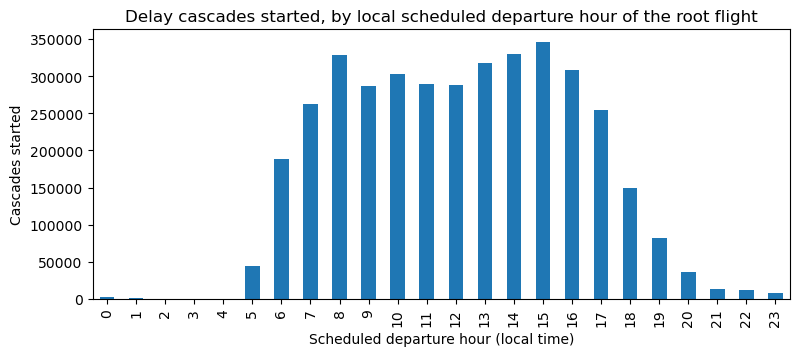

In [13]:
by_hr = (cascades.groupBy("root_local_hour").agg(F.count("*").alias("cascades"), F.avg("chain_len").alias("avg_len"))
         .orderBy("root_local_hour").toPandas())
ax = by_hr.plot(x="root_local_hour", y="cascades", kind="bar", legend=False, figsize=(9,3.5),
                title="Delay cascades started, by local scheduled departure hour of the root flight")
ax.set_xlabel("Scheduled departure hour (local time)"); ax.set_ylabel("Cascades started"); plt.show()

## 6 · Weather at the origin (NOAA hourly, top-50 airports)
Weather times may be local standard time or UTC depending on the product, so the notebook **checks** instead of assuming: temperature peaks mid-afternoon *local* time (~14–16 h), so the hour of the temperature peak shows which clock `DATE` uses.

In [14]:
wx_raw = spark.read.parquet(str(WX_PQ))
print(f"{wx_raw.count():,} observations;", wx_raw.select("airport").distinct().count(), "airports")
# Spark 4 runs in ANSI mode: casting "" or text to double would raise, so empty matches become NULL first
num = lambda c: F.nullif(F.regexp_extract(F.col(c), r"(-?\d+\.?\d*)", 1), F.lit("")).cast("double")
wx0 = (wx_raw.withColumn("obs", F.try_to_timestamp("DATE"))
             .withColumn("temp", num("HourlyDryBulbTemperature"))
             .withColumn("vis",  num("HourlyVisibility"))
             .withColumn("precip", F.when(F.trim(F.col("HourlyPrecipitation")).startswith("T"), F.lit(0.0)).otherwise(num("HourlyPrecipitation")))
             .withColumn("wtype", F.coalesce(F.col("HourlyPresentWeatherType"), F.lit(""))))
wx0.select("airport","DATE","HourlyDryBulbTemperature","HourlyVisibility","HourlyPrecipitation","HourlyPresentWeatherType").show(5, truncate=40)

10,660,339 observations; 50 airports
+-------+-------------------+------------------------+----------------+-------------------+------------------------+
|airport|               DATE|HourlyDryBulbTemperature|HourlyVisibility|HourlyPrecipitation|HourlyPresentWeatherType|
+-------+-------------------+------------------------+----------------+-------------------+------------------------+
|    CLE|2011-01-01T00:00:00|                    NULL|            NULL|               NULL|                    NULL|
|    CLE|2011-01-01T00:51:00|                    13.3|          16.093|                0.0|                    NULL|
|    CLE|2011-01-01T01:00:00|                    13.3|            NULL|               NULL|                    NULL|
|    CLE|2011-01-01T01:51:00|                    13.3|          16.093|                0.0|                    NULL|
|    CLE|2011-01-01T02:51:00|                    13.3|          16.093|                0.0|                    NULL|
+-------+------------------

ORD July temperature peaks at hour 14 of DATE  ->  DATE is on the LOCAL clock


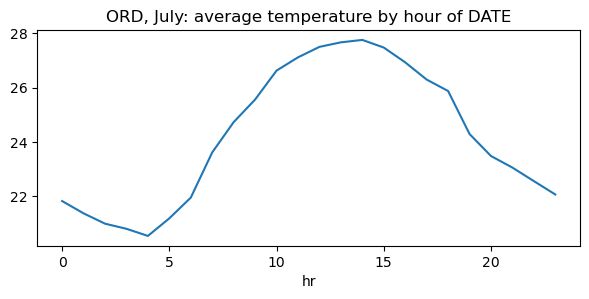

99.9th percentile visibility = 16.093  ->  units look metric; low-visibility < 5.0, heavy precip >= 2.5


In [15]:
# (1) which clock is DATE on?  average July temperature by hour of DATE for ORD
peak = (wx0.filter((F.col("airport") == "ORD") & (F.month("obs") == 7) & F.col("temp").isNotNull())
           .groupBy(F.hour("obs").alias("hr")).agg(F.avg("temp").alias("avg_temp")).orderBy("hr").toPandas())
peak_hr = int(peak.loc[peak.avg_temp.idxmax(), "hr"])
WX_CLOCK = "local" if 11 <= peak_hr <= 18 else "utc"
print(f"ORD July temperature peaks at hour {peak_hr} of DATE  ->  DATE is on the {WX_CLOCK.upper()} clock")
peak.plot(x="hr", y="avg_temp", figsize=(7,2.8), legend=False, title="ORD, July: average temperature by hour of DATE"); plt.show()

# (2) units: US (miles / inches) or metric (km / mm)?  US visibility tops out at 10 miles; metric at ~16 km
vmax = wx0.agg(F.expr("percentile_approx(vis, 0.999)")).first()[0]
UNITS = "metric" if vmax > 12 else "us"
VIS_BAD, PRECIP_BAD = (5.0, 2.5) if UNITS == "metric" else (3.0, 0.10)     # km/mm  or  miles/inches
print(f"99.9th percentile visibility = {vmax}  ->  units look {UNITS}; low-visibility < {VIS_BAD}, heavy precip >= {PRECIP_BAD}")

In [16]:
# standard-time offset per airport (only needed if DATE is local standard time)
import datetime as dt
from zoneinfo import ZoneInfo
tzdf = (spark.read.csv(str(TZ_CSV), header=True).toPandas() if RUN_ON == "gcp" else pd.read_csv(TZ_CSV))
std = {r.Origin: dt.datetime(2024, 1, 15, 12, tzinfo=ZoneInfo(r.tz)).utcoffset().total_seconds() for r in tzdf.itertuples()}
std_sdf = F.broadcast(spark.createDataFrame(pd.DataFrame({"airport": list(std), "std_off_s": list(std.values())})))

SEVERE = r"(TS|SN|FZ|FG|GR|PL|SG|IC|FC|SQ|DS|SS)"          # thunderstorm, snow, freezing, fog, hail, pellets, funnel cloud, squall, dust/sand
wx = wx0.join(std_sdf, "airport", "left")
obs_utc = (F.col("obs") if WX_CLOCK == "utc"
           else F.timestamp_seconds(F.unix_timestamp("obs") - F.col("std_off_s")))
wx = wx.withColumn("obs_utc", obs_utc).withColumn("wx_hour", F.date_trunc("hour", "obs_utc"))
if RUN_YEARS: wx = wx.filter(F.year("wx_hour").isin(RUN_YEARS))
wx_hourly = (wx.groupBy("airport", "wx_hour")
               .agg(F.min("vis").alias("vis_min"), F.max("precip").alias("precip_max"),
                    F.avg("temp").alias("temp_avg"), F.max(F.col("wtype").rlike(SEVERE).cast("int")).alias("severe_type"))
               .withColumn("wx_bad", (F.col("severe_type") == 1) | (F.col("vis_min") < VIS_BAD) | (F.col("precip_max") >= PRECIP_BAD)))
print(f"{wx_hourly.count():,} airport-hours;  share flagged bad weather: "
      f"{wx_hourly.agg(F.avg(F.col('wx_bad').cast('double'))).first()[0]:.3f}")

7,367,284 airport-hours;  share flagged bad weather: 0.070


## 7 · Join weather to flights (origin airport, UTC hour of scheduled departure) and classify delays

In [17]:
ff = (pairs.withColumn("dep_hour", F.date_trunc("hour", "sched_dep_utc"))
           .join(wx_hourly, (F.col("Origin") == F.col("airport")) & (F.col("dep_hour") == F.col("wx_hour")), "left")
           .withColumn("has_wx", F.col("wx_hour").isNotNull())
           .withColumn("delay_class",
               F.when(F.col("DepDelay") < DELAY_MIN, "on time (<15 min)")
                .when(F.col("inherited_min") >= DELAY_MIN, "inherited (late aircraft)")
                .when(~F.col("has_wx"), "no weather data (airport outside top 50)")
                .when(F.col("wx_bad"), "weather at origin")
                .otherwise("other (carrier / ATC / unknown)")))
(ff.drop("airport", "wx_hour").write.mode("overwrite").partitionBy("Year").parquet(str(OUT/"flights_features")))
ff = spark.read.parquet(str(OUT/"flights_features"))
top50 = ff.filter("has_wx")
print(f"flights with weather: {top50.count():,} of {ff.count():,}")

flights with weather: 81,562,280 of 103,396,805


In [18]:
# how are delayed departures (15+ min) at the weather airports explained?
cls = (top50.filter(F.col("DepDelay") >= DELAY_MIN).groupBy("delay_class")
       .agg(F.count("*").alias("delayed_flights"), F.sum("DepDelay").alias("delay_minutes")).toPandas())
cls["share_of_flights_%"]  = (100 * cls.delayed_flights / cls.delayed_flights.sum()).round(1)
cls["share_of_minutes_%"]  = (100 * cls.delay_minutes / cls.delay_minutes.sum()).round(1)
cls.sort_values("delayed_flights", ascending=False)

,delay_class,delayed_flights,delay_minutes,share_of_flights_%,share_of_minutes_%
0,other (carrier / ATC / unknown),10067650,548731800.0,63.3,55.1
1,inherited (late aircraft),4785397,371089867.0,30.1,37.3
2,weather at origin,1055021,75737757.0,6.6,7.6


In [19]:
# ask it twice: BTS's own cause minutes (only filled for delays of 15+ min) vs. our weather class
bts = (top50.filter(F.col("ArrDelay") >= DELAY_MIN)
       .agg(F.sum("CarrierDelay").alias("carrier"), F.sum("WeatherDelay").alias("weather"), F.sum("NASDelay").alias("nas"),
            F.sum("SecurityDelay").alias("security"), F.sum("LateAircraftDelay").alias("late_aircraft")).toPandas().iloc[0])
print((100 * bts / bts.sum()).round(1).to_string())
print("\n(BTS 'weather' is only extreme weather; 'nas' includes weather-related air-traffic control delay, so compare orders of magnitude, not exact values.)")

carrier          33.5
weather           5.1
nas              22.1
security          0.2
late_aircraft    39.2

(BTS 'weather' is only extreme weather; 'nas' includes weather-related air-traffic control delay, so compare orders of magnitude, not exact values.)


In [20]:
# does bad weather at the origin raise the average delay?  (top-50 airports)
(top50.groupBy("wx_bad").agg(F.count("*").alias("flights"), F.round(F.avg("DepDelay"), 1).alias("avg_dep_delay"),
                             F.round(100 * F.avg((F.col("DepDelay") >= DELAY_MIN).cast("double")), 1).alias("pct_delayed_15"))
      .orderBy("wx_bad").show())

+------+--------+-------------+--------------+
|wx_bad| flights|avg_dep_delay|pct_delayed_15|
+------+--------+-------------+--------------+
|  NULL| 5166942|         12.7|          22.2|
| false|71264903|          9.5|          18.6|
|  true| 5130435|         22.5|          30.0|
+------+--------+-------------+--------------+



## 7b · What starts cascades? Weather at the *first* delayed flight
The table above only counts weather at the airport where a flight departs. Cascades are better explained by their **root**: how often was there bad weather at the origin of the flight that started the chain, compared with an ordinary flight?

In [21]:
wf = ff.filter(F.col("has_wx")).withColumn("wxb", F.coalesce(F.col("wx_bad"), F.lit(False)).cast("double"))
roots = wf.filter(F.col("depth") == 0)

baseline = wf.agg(F.count("*").alias("flights"), F.round(100 * F.avg("wxb"), 1).alias("pct_bad_weather_at_origin")).toPandas()
baseline.insert(0, "group", "all flights (baseline)")

grp = (roots.filter(F.col("DepDelay") >= DELAY_MIN)
       .withColumn("group", F.when(F.col("chain_len") >= 2, "root of a cascade (>=1 later flight inherits delay)")
                             .otherwise("delayed, but no later flight inherits"))
       .groupBy("group").agg(F.count("*").alias("flights"), F.round(100 * F.avg("wxb"), 1).alias("pct_bad_weather_at_origin")).toPandas())
display(pd.concat([baseline, grp], ignore_index=True))

# longer cascades: is weather more likely at their root?
by_len = (roots.filter((F.col("DepDelay") >= DELAY_MIN) & (F.col("chain_len") >= 2))
          .withColumn("cascade_size", F.when(F.col("chain_len") >= 5, "5+").otherwise(F.col("chain_len").cast("string")))
          .groupBy("cascade_size").agg(F.count("*").alias("cascades"), F.round(100 * F.avg("wxb"), 1).alias("pct_root_bad_weather"))
          .orderBy("cascade_size").toPandas())
display(by_len)

,group,flights,pct_bad_weather_at_origin
0,all flights (baseline),81562280,6.3
1,"delayed, but no later flight inherits",5774595,8.8
2,root of a cascade (>=1 later flight inherits d...,3333918,11.4


,cascade_size,cascades,pct_root_bad_weather
0,2,2012295,10.4
1,3,755997,12.5
2,4,334257,12.6
3,5+,231369,14.1


In [22]:
# by airport: cascades started, and the share whose root flight had bad weather there
by_ap_wx = (roots.filter((F.col("DepDelay") >= DELAY_MIN) & (F.col("chain_len") >= 2))
            .groupBy("Origin").agg(F.count("*").alias("cascades"), F.round(100 * F.avg("wxb"), 1).alias("pct_root_bad_weather"))
            .orderBy(F.desc("cascades")).limit(15).toPandas())
by_ap_wx

,Origin,cascades,pct_root_bad_weather
0,DFW,271967,8.2
1,ATL,262670,13.0
2,ORD,260481,14.5
3,DEN,193020,13.0
4,CLT,129378,11.0
5,PHX,106998,1.5
6,IAH,105201,13.7
7,LAX,103894,8.8
8,LAS,97203,2.0
9,MCO,97158,15.9


## 8 · Summary table for MongoDB Atlas / the dashboard

In [23]:
summary = (cascades.groupBy("root_origin", "root_local_hour")
           .agg(F.count("*").alias("cascades"), F.round(F.avg("chain_len"), 2).alias("avg_chain_len"),
                F.round(F.sum("downstream_inherited_min"), 0).alias("inherited_minutes"))
           .withColumnRenamed("root_origin", "airport").withColumnRenamed("root_local_hour", "local_hour"))
summary.coalesce(1).write.mode("overwrite").parquet(str(OUT/"summary_airport_hour"))
print(summary.count(), "airport-hour rows;", f"folder: {OUT/'summary_airport_hour'}")
summary.orderBy(F.desc("cascades")).show(10)

5652 airport-hour rows; folder: gs://flightdelay-olivia-2026/gold/summary_airport_hour


+-------+----------+--------+-------------+-----------------+
|airport|local_hour|cascades|avg_chain_len|inherited_minutes|
+-------+----------+--------+-------------+-----------------+
|    DFW|        12|   32927|         2.47|        2427470.0|
|    ATL|        15|   32149|         2.33|        2182120.0|
|    DFW|        10|   32143|         2.62|        2538023.0|
|    DFW|        14|   31406|         2.34|        2134709.0|
|    ATL|        16|   31152|         2.28|        2020817.0|
|    ORD|        13|   28778|         2.53|        2418889.0|
|    ORD|         8|   28227|         2.89|        2746873.0|
|    DEN|        11|   26839|         2.72|        2051995.0|
|    ORD|        10|   24884|         2.72|        2237330.0|
|    ORD|         9|   24712|         2.77|        2206549.0|
+-------+----------+--------+-------------+-----------------+
only showing top 10 rows

